In [1]:
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

main_dir = '/home/gap2/Downloads/PPRL-Dev-main/results/clustering/D8/'

In [2]:
df_cosine = pd.read_csv(main_dir + 'KiralyMSMApproximateClustering_cosine.csv')
df_cosine['similarity'] = 'cosine'
df_dice = pd.read_csv(main_dir + 'KiralyMSMApproximateClustering_dice.csv')
df_dice['similarity'] = 'dice'
df_jaccard = pd.read_csv(main_dir + 'KiralyMSMApproximateClustering_jaccard.csv')
df_jaccard['similarity'] = 'jaccard'
#df_scm = pd.read_csv(main_dir + 'KiralyMSMApproximateClustering_scm.csv')
#df_scm['similarity'] = 'scm'

In [3]:
result = pd.DataFrame()
dfs = [df_cosine, df_dice, df_jaccard]#, df_scm]
for df in dfs:
    result = pd.concat([result, df], ignore_index=True, sort=False)

result['config_dict'] = result['config'].apply(ast.literal_eval)
config_cols = pd.json_normalize(result['config_dict'])
result = result.join(config_cols)
result = result.drop(columns=['config', 'config_dict'])
result

,name,total_clusters,threshold,matcher,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
0,Clustering with KiralyMSMApproximateClustering,22607,0.30,cosine,26.75,63.19,37.59,539,1476,23455,314,cosine,[title],1024,0,1,salted_qgrams,,4
1,Clustering with KiralyMSMApproximateClustering,22839,0.50,cosine,29.44,61.55,39.83,525,1258,23441,328,cosine,[title],1024,0,1,salted_qgrams,,4
2,Clustering with KiralyMSMApproximateClustering,22677,0.40,cosine,27.56,62.84,38.31,536,1409,23452,317,cosine,[title],1024,0,1,salted_qgrams,,4
3,Clustering with KiralyMSMApproximateClustering,22598,0.20,cosine,26.63,63.19,37.47,539,1485,23455,314,cosine,[title],1024,0,1,salted_qgrams,,4
4,Clustering with KiralyMSMApproximateClustering,23548,0.70,cosine,39.76,50.06,44.32,427,647,23343,426,cosine,[title],1024,0,1,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1819,Clustering with KiralyMSMApproximateClustering,1577,0.55,jaccard,20.93,38.69,27.16,330,1247,23246,523,jaccard,[title],1024,0,32,salted_qgrams,,4
1820,Clustering with KiralyMSMApproximateClustering,1502,0.65,jaccard,27.76,48.89,35.41,417,1085,23333,436,jaccard,[title],1024,0,32,salted_qgrams,,4
1821,Clustering with KiralyMSMApproximateClustering,1034,0.75,jaccard,34.82,42.20,38.16,360,674,23276,493,jaccard,[title],1024,0,32,salted_qgrams,,4
1822,Clustering with KiralyMSMApproximateClustering,462,0.85,jaccard,47.19,25.56,33.16,218,244,23134,635,jaccard,[title],1024,0,32,salted_qgrams,,4


In [4]:
result['attributes'].value_counts()

attributes
[title]    1824
Name: count, dtype: int64

In [5]:
result['offset'].value_counts()

offset
0    1824
Name: count, dtype: int64

In [6]:
result['hashing_type'].value_counts()

hashing_type
salted_qgrams    1824
Name: count, dtype: int64

In [7]:
result['qgrams'].value_counts()

qgrams
4    1824
Name: count, dtype: int64

In [8]:
result['size'].value_counts()

size
1024    1824
Name: count, dtype: int64

In [9]:
result['num_hashes'].value_counts()

num_hashes
1     57
2     57
3     57
4     57
5     57
6     57
7     57
8     57
9     57
10    57
11    57
12    57
13    57
14    57
15    57
16    57
17    57
18    57
19    57
20    57
21    57
22    57
23    57
24    57
25    57
26    57
27    57
28    57
29    57
30    57
31    57
32    57
Name: count, dtype: int64

In [10]:
max_f1 = result.loc[result.groupby(['num_hashes','similarity'])['F1 %'].idxmax()]
max_f1

,name,total_clusters,threshold,matcher,Precision %,Recall %,F1 %,True Positives,False Positives,True Negatives,False Negatives,similarity,attributes,size,offset,num_hashes,hashing_type,salt,qgrams
4,Clustering with KiralyMSMApproximateClustering,23548,0.70,cosine,39.76,50.06,44.32,427,647,23343,426,cosine,[title],1024,0,1,salted_qgrams,,4
608,Clustering with KiralyMSMApproximateClustering,23610,0.70,dice,40.22,47.71,43.65,407,605,23323,446,dice,[title],1024,0,1,salted_qgrams,,4
1509,Clustering with KiralyMSMApproximateClustering,966,0.55,jaccard,40.89,46.31,43.43,395,571,23311,458,jaccard,[title],1024,0,1,salted_qgrams,,4
13,Clustering with KiralyMSMApproximateClustering,23524,0.70,cosine,39.53,50.88,44.49,434,664,23350,419,cosine,[title],1024,0,2,salted_qgrams,,4
620,Clustering with KiralyMSMApproximateClustering,23578,0.70,dice,39.27,48.07,43.23,410,634,23326,443,dice,[title],1024,0,2,salted_qgrams,,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1204,Clustering with KiralyMSMApproximateClustering,1060,0.85,dice,34.72,43.14,38.47,368,692,23284,485,dice,[title],1024,0,31,salted_qgrams,,4
1493,Clustering with KiralyMSMApproximateClustering,691,0.80,jaccard,43.70,35.40,39.12,302,389,23218,551,jaccard,[title],1024,0,31,salted_qgrams,,4
606,Clustering with KiralyMSMApproximateClustering,1087,0.85,cosine,34.87,44.43,39.07,379,708,23295,474,cosine,[title],1024,0,32,salted_qgrams,,4
1214,Clustering with KiralyMSMApproximateClustering,1086,0.85,dice,33.98,43.26,38.06,369,717,23285,484,dice,[title],1024,0,32,salted_qgrams,,4


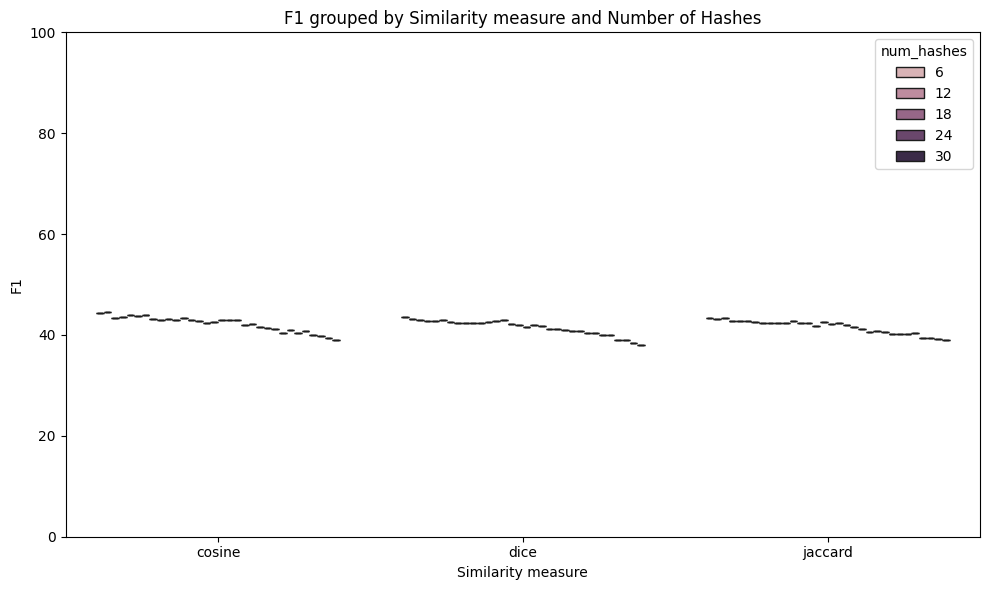

In [11]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=max_f1,
    x="similarity",
    y="F1 %",
    hue="num_hashes"
)

plt.title("F1 grouped by Similarity measure and Number of Hashes")
plt.xlabel("Similarity measure")
plt.ylabel("F1")
plt.ylim(0, 100) 
plt.legend(title="num_hashes")
plt.tight_layout()
plt.show()

In [12]:
metrics_df = max_f1.melt(
    id_vars=["similarity", "num_hashes"],
    value_vars=["Precision %", "Recall %", "F1 %"],
    var_name="Metric",
    value_name="Score"
)
metrics_df

,similarity,num_hashes,Metric,Score
0,cosine,1,Precision %,39.76
1,dice,1,Precision %,40.22
2,jaccard,1,Precision %,40.89
3,cosine,2,Precision %,39.53
4,dice,2,Precision %,39.27
...,...,...,...,...
283,dice,31,F1 %,38.47
284,jaccard,31,F1 %,39.12
285,cosine,32,F1 %,39.07
286,dice,32,F1 %,38.06


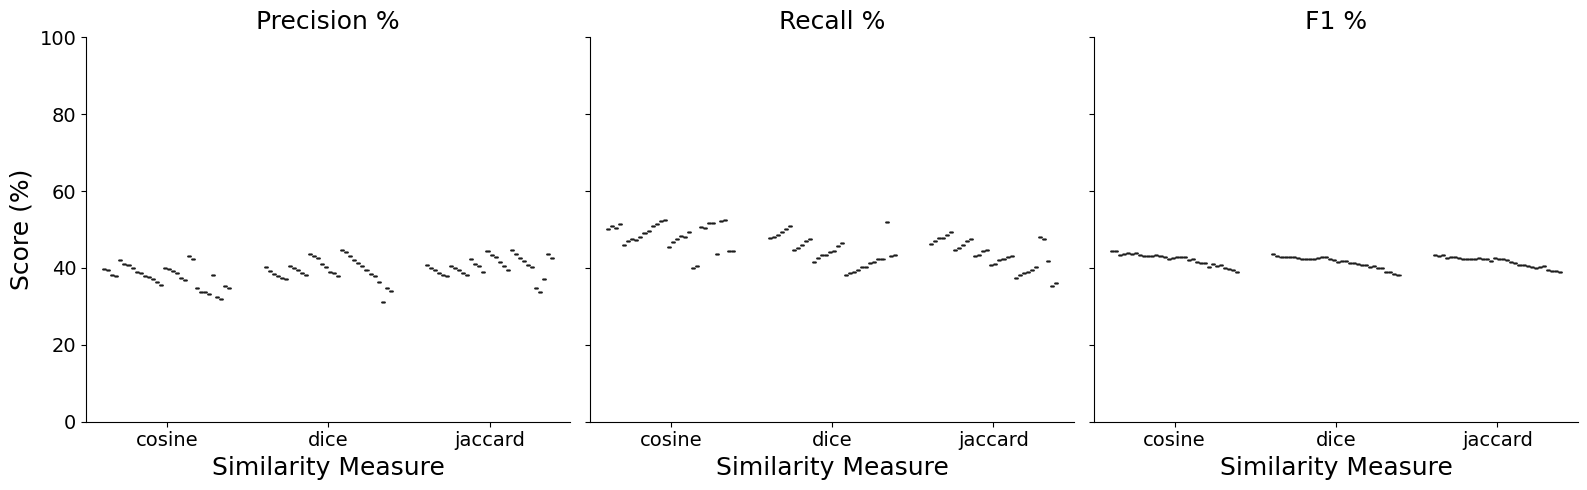

In [13]:
g = sns.catplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="num_hashes",
    col="Metric",
    kind="box",
    height=5,
    aspect=1,
    fliersize=14  # increase dot size
)
g._legend.remove()
g.set(ylim=(0, 100))
g.set_axis_labels("Similarity Measure", "Score (%)", fontsize=18)
g.set_titles("{col_name}", size=18)
for ax in g.axes.flat:
    ax.tick_params(axis='both', labelsize=14)
plt.tight_layout()
plt.show()

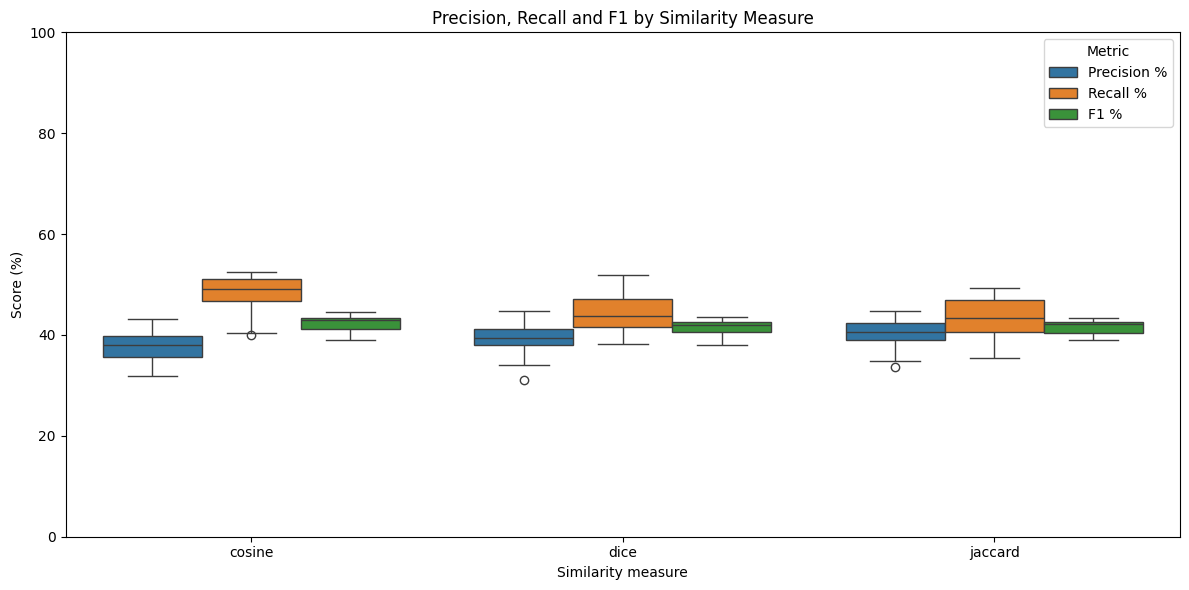

In [14]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=metrics_df,
    x="similarity",
    y="Score",
    hue="Metric"
)

plt.title("Precision, Recall and F1 by Similarity Measure")
plt.xlabel("Similarity measure")
plt.ylabel("Score (%)")
plt.ylim(0, 100) 
plt.legend(title="Metric")
plt.tight_layout()
plt.show()